#HW1 - Flavors of Cacao



## Introduction
In this assignment you will be doing some initial data management and simple exploration using Python.   Use of the Gemini tools within Colab is allowed, but **please attempt the problems without inline AI assistance** - by going to Settings in Colab via the gear icon ⚙ => AI Assistance => uncheck "Show AI Powered Inline Completions".   This will allow you to attempt to code without AI shoving the answer in your face.  You can always ask for AI assistance using the Gemini star icon ⭐ at the bottom of the page.   But you will learn more by trying things yourself first.

**Note - several questions ask for interpretations of the code output or thoughts about the problem.  Your answer is not complete without these intepretations.  Add a text box below your code to answer any interpreatation questions.**

**Please do not use AI for any opinion or interpretive questions.**

Submit homework to Brightspace in the form of a file named **`lastname_firstname.ipynb`**


---

##<h3>**Before you start!**</h3>

*Save a copy of this file to your own Google Drive (and make sure you are on the correct Google account!)*

---

## Flavors of Cacao Dataset

Use Case:  You are working for a small batch chocolatier in Brooklyn.  Your chocolates have gotten a small but passionate following amongst friends and you are starting to get some attention.  You would like to expand your options to appeal to a broader customer base, and perhaps break out of your region.  

In order to understand the market better, you come across a data set of chocolate tastings, on the website [Flavors of Cacao](https://flavorsofcacao.com/chocolate_database.html).  Take a look at the data available on that site, it has thousands of ratings of chocolate bars, along with characteristics of the bars from human raters.


1.  **Describe in a few sentences how you might use this data to help you design and market a new chocolate bar for your catalog.   Specifically, your partner Charlie proposes that you sort the beans by rating, find the three highest rated beans, and create bars from a combination of those beans.  What critiques do you have for Charlie's proposal?**

- different flavor profiles mixed together may not be good even if the individual beans rate very highly
- certain beans may be too expensive per quantity (if not by bean price, than from shipping from remote locations) to be usable for a small chocalatier
- does not take into account the tastes of the NYC/American customer base

more intrinsic issues with the database:
- there are doezens of beans all with a rating of 4, and seemingly no way to discern them
- many of the ratings are many years old and the farm products may be of very different quality by now

2. **[Import the data locally using this link](https://drive.google.com/uc?export=download&id=1vzPK4RuM6X3JpHLPEjBe9gvQru5LECE1).  Then import into Colab using the left hand menu as we showed in class.   Import the appropriate Python libraries (`pandas, numpy, matplotlib, and seaborn`), and read the file into your session using `read_excel` from pandas.  Report on the number of rows and columns in the data.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# read file in using pd.read_excel()
...
df = pd.read_excel('chocolate_ratings.xlsx')
df.info()
# 2789 rows, 10 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   REF                               2789 non-null   int64  
 1   Company..Manufacturer.            2789 non-null   object 
 2   Company.Location                  2789 non-null   object 
 3   Review.Date                       2789 non-null   int64  
 4   Country.of.Bean.Origin            2789 non-null   object 
 5   Specific.Bean.Origin.or.Bar.Name  2789 non-null   object 
 6   Cocoa.Percent                     2789 non-null   object 
 7   Ingredients                       2702 non-null   object 
 8   Most.Memorable.Characteristics    2789 non-null   object 
 9   Rating                            2789 non-null   float64
dtypes: float64(1), int64(2), object(7)
memory usage: 218.0+ KB


3. **Inspect the data using `.head()` and `.info()`.    It is bad form to have dots in feature names, and these names are kind of unwieldy.  Use `.rename` to create shorter, more compact feature names without punctuation (e.g. `CocoaPercent`).    Which of the features do you think are going to be the most useful for your exploration?**


In [2]:
# refer to previous problem for df.info()
df.head()

,REF,Company..Manufacturer.,Company.Location,Review.Date,Country.of.Bean.Origin,Specific.Bean.Origin.or.Bar.Name,Cocoa.Percent,Ingredients,Most.Memorable.Characteristics,Rating
0,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
3,2542,5150,U.S.A.,2021,India,"Anamalai, batch 1",68%,"3- B,S,C","milk brownie, macadamia,chewy",3.50
4,2546,5150,U.S.A.,2021,Uganda,"Semuliki Forest, batch 1",80%,"3- B,S,C","mildly bitter, basic cocoa, fatty",3.25


In [3]:
df = df.rename(columns = lambda i: i.replace('.',''))
df.head()

# debugging funny- misspelled lambda as lamda (its been a while)

,REF,CompanyManufacturer,CompanyLocation,ReviewDate,CountryofBeanOrigin,SpecificBeanOriginorBarName,CocoaPercent,Ingredients,MostMemorableCharacteristics,Rating
0,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
3,2542,5150,U.S.A.,2021,India,"Anamalai, batch 1",68%,"3- B,S,C","milk brownie, macadamia,chewy",3.50
4,2546,5150,U.S.A.,2021,Uganda,"Semuliki Forest, batch 1",80%,"3- B,S,C","mildly bitter, basic cocoa, fatty",3.25


4.  **Report whether there  any missing values for any feature (using `isnull()`).  How might you deal with this issue?**

In [4]:
df.isnull().sum()
# all of the null values are in "Ingredients"

REF                              0
CompanyManufacturer              0
CompanyLocation                  0
ReviewDate                       0
CountryofBeanOrigin              0
SpecificBeanOriginorBarName      0
CocoaPercent                     0
Ingredients                     87
MostMemorableCharacteristics     0
Rating                           0
dtype: int64

In [5]:
df[df['Ingredients'].isnull()].sort_values(by='Rating', ascending=False).head(50)
# 87 out of 2789 and with a fairly limited number of 'high rating' cacao makes it feasible to either completely ignore/drop the results
# alternatively, manually research the ingredients for each one that you could consider using (i.e. the sole 4.0 rating one)
# also possible to just avoid relying on ingredients as a compononent of the model, if it turns out to be less useful than other characteristics

,REF,CompanyManufacturer,CompanyLocation,ReviewDate,CountryofBeanOrigin,SpecificBeanOriginorBarName,CocoaPercent,Ingredients,MostMemorableCharacteristics,Rating
2586,895,Tobago Estate (Pralus),France,2012,Tobago,"Roxborough, Tobago",70%,NaN,"smooth, wild berries",4.00
642,666,Christopher Morel (Felchlin),Canada,2011,Peru,"Maranon Canyon, Fortunato No. 4",68%,NaN,"oily, citrus, orange",3.75
1419,387,Kakao,Germany,2009,Vanuatu,Vanuatu,65%,NaN,"cocoa, strong distinct spice",3.75
2618,709,Un Dimanche A Paris,France,2011,Dominican Republic,Dominican Republic,63%,NaN,spicy and rich,3.75
840,311,Dole (Guittard),U.S.A.,2009,U.S.A.,"O'ahu Island, N. Shore, Waialua Estate",70%,NaN,"creamy, nutty, fruity",3.75
657,292,Compania de Chocolate (Salgado),Argentina,2008,Venezuela,Ocumare,70%,NaN,"minty, nutty, nutmeg",3.75
1864,1007,Nanea,U.S.A.,2013,U.S.A.,Criollo Blend,85%,NaN,"sandy, spicy, earthy",3.50
1843,1658,Montecristi,Ecuador,2015,Ecuador,Manabi,85%,NaN,"spicy, fragrant, bitter",3.50
1842,1654,Montecristi,Ecuador,2015,Ecuador,Manabi,63%,NaN,"spicy, sweet, fragrant",3.50
2207,923,Rococo (Grenada Chocolate Co.),U.K.,2012,Grenada,"Gru Grococo, St. Andrews",66%,NaN,"earthy, mild nutty",3.50


5. **Report on the number of bars that are manufactured in Brazil as compared to the number of bars that come from Brazilian beans.**

In [6]:
((df['CompanyLocation'] == 'Brazil') & (df['CountryofBeanOrigin'] != 'Brazil')).sum()
# check for the possiblity of non-brazilian beans being processed in brazil
# I think the spirit fo the question is more "how many of Brazil's beans are processed in the same country" so I'm excluding that result in ratio

1

In [7]:
brOrigin = (df['CountryofBeanOrigin'] == 'Brazil').sum()
brManafacture = (df['CompanyLocation'] == 'Brazil').sum()
brBoth = ((df['CompanyLocation'] == 'Brazil') & (df['CountryofBeanOrigin'] == 'Brazil')).sum()

print(f'Brazilian beans: {brOrigin}')
print(f'Brazilian manafacturer: {brManafacture}')
print(f'Brazilian everything: {brBoth}')
print(f'Ratio: {(brBoth/brOrigin).round(4)}')

Brazilian beans: 83
Brazilian manafacturer: 27
Brazilian everything: 26
Ratio: 0.3133


6.  **Charlie suggests that you source your beans from the country that has the highest rated bars.  Use a `.groupby()` to find the `CountryofBeanOrigin` that has the highest average (mean) `Rating`.   How many bars have that country of origin?  Would you recommend sourcing beans from that country?**


In [8]:
df.groupby(['CountryofBeanOrigin'])['Rating'].mean().sort_values() 
#Tobago

CountryofBeanOrigin
Bali                   2.500000
Puerto Rico            2.714286
Sierra Leone           2.750000
Benin                  2.750000
Principe               2.750000
                         ...   
Thailand               3.300000
Congo                  3.318182
Solomon Islands        3.450000
Sao Tome & Principe    3.500000
Tobago                 3.625000
Name: Rating, Length: 66, dtype: float64

In [9]:
df[df['CountryofBeanOrigin'] == 'Tobago']
# not enough, clearly
# I would NOT source from Tobago

,REF,CompanyManufacturer,CompanyLocation,ReviewDate,CountryofBeanOrigin,SpecificBeanOriginorBarName,CocoaPercent,Ingredients,MostMemorableCharacteristics,Rating
1502,1145,La Maison du Chocolat (Valrhona),France,2013,Tobago,Tobago,60%,"4- B,S,C,L","creamy, rich, dairy, nutty",3.25
2586,895,Tobago Estate (Pralus),France,2012,Tobago,"Roxborough, Tobago",70%,NaN,"smooth, wild berries",4.00


7.  **We want to explore the relationship between CocoaPercent and Rating.  Note that CocoaPercent initially has a percent sign and was probably imported as a character (or `object`), so create a numeric version of this feature first.   Then calculate the correlation between CocoaPercent and Rating.   Interpret this number.**

In [10]:
df['CocoaPercentFloat'] = df['CocoaPercent'].str[:-1].astype(float) / 100 # originally tried to do float() oops!
df['CocoaPercentFloat']

0       0.76
1       0.76
2       0.76
3       0.68
4       0.80
        ... 
2784    0.80
2785    0.75
2786    0.72
2787    0.70
2788    0.75
Name: CocoaPercentFloat, Length: 2789, dtype: float64

In [11]:
df['CocoaPercentFloat'].corr(df['Rating'])
# *weak* negative correlation-- low cocoa% is barely more likely to be rated highly

-0.13897325934153512

8. **Plot a scatterplot using `.scatterplot()` from `seaborn` library of the numeric CocoaPercent vs. Rating.   What do you conclude about the relationship from this scatterplot?  Can you see any problems or issues with this plot?**

<Axes: xlabel='Rating', ylabel='CocoaPercentFloat'>

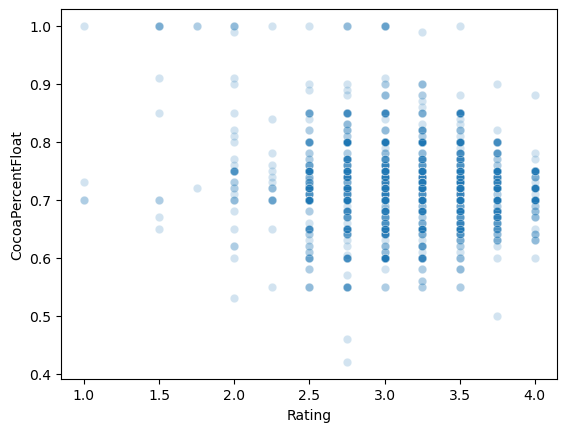

In [12]:
sns.scatterplot(df, x='Rating', y='CocoaPercentFloat', alpha=0.2)
# very weak correlation, although it seems that the spread seems to narrow for the absolute highest ratings
# perhaps try nonlinear correlations?
# the concrete steps in ratings makes the scatterplot look very jarring(?)
# cocoa% also has the same issue; 100 steps is very little in thousands of results + many sit at the same 65/70/80 numbers
# even with heavy alpha, it's very dfficult to discern how many samples overlap at the same points

9. **Now create a binned version of `CocoaPercent` (e.g. 50-60%, 60-70%, etc) and calculate the average `Rating` within each bin. (you can do this with `.cut()` and `.groupby()`)  Does your interpretation of the relationship between CocoaPercent and Rating change?**

In [13]:
#from the scatterplot we know that 40% is the floor
df.groupby(pd.cut(df['CocoaPercentFloat'], bins=[.5, .6, .7, .8, .9, 1]))['Rating'].mean()

# the highest ratings are in the 0.6-0.8 range with significant drop off for low and (especially) high cocoa percentages
# lines up with my observation of the "spread" narrowing for higher ratings

/var/folders/cp/_9p85_dj3_d6pp41cqbmlk_m0000gn/T/ipykernel_81776/2047479453.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.cut(df['CocoaPercentFloat'], bins=[.5, .6, .7, .8, .9, 1]))['Rating'].mean()


CocoaPercentFloat
(0.5, 0.6]    2.976974
(0.6, 0.7]    3.254115
(0.7, 0.8]    3.170327
(0.8, 0.9]    3.010526
(0.9, 1.0]    2.298077
Name: Rating, dtype: float64

In [14]:
df.groupby(['Rating'])['CocoaPercentFloat'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])

# as you can see the std of cocoa% drops off sharply as the ratings climb

,count,mean,std,min,median,max
Rating,,,,,,
1.00,4,0.782500,0.145688,0.70,0.715,1.00
1.50,10,0.848000,0.153101,0.65,0.880,1.00
1.75,3,0.906667,0.161658,0.72,1.000,1.00
2.00,33,0.765758,0.116968,0.53,0.750,1.00
2.25,17,0.732941,0.090951,0.55,0.720,1.00
2.50,184,0.716875,0.061167,0.55,0.700,1.00
2.75,358,0.720056,0.063973,0.42,0.700,1.00
3.00,593,0.715843,0.054563,0.55,0.700,1.00
3.25,519,0.714239,0.049765,0.55,0.700,0.99


10. **Explore the data further and comment on one other finding you personally find interesting.**  

In [15]:
# trying to find something interesting to talk about
for i in df.columns[1:-2]: # remove index and rating from the display
    out = df.groupby([i])['Rating'].agg(['count', 'mean', 'std', 'min', 'median', 'max']).sort_values(by='mean', ascending=False).head(10)
    print(out)

# seems like fun to categorize by characteristics-- will have to explode the df to allow for row to appear in multiple bins

                                      count      mean       std   min  median  \
CompanyManufacturer                                                             
Tobago Estate (Pralus)                    1  4.000000       NaN  4.00   4.000   
Ocelot                                    2  3.875000  0.176777  3.75   3.875   
Heirloom Cacao Preservation (Zokoko)      2  3.875000  0.176777  3.75   3.875   
Matale                                    4  3.812500  0.239357  3.50   3.875   
Patric                                    6  3.791667  0.245798  3.50   3.875   
Cuna de Piedra                            1  3.750000       NaN  3.75   3.750   
Nikoa                                     1  3.750000       NaN  3.75   3.750   
Un Dimanche A Paris                       1  3.750000       NaN  3.75   3.750   
Obolo                                     2  3.750000  0.000000  3.75   3.750   
Goodnow                                   1  3.750000       NaN  3.75   3.750   

                           

In [ ]:
# df['charList'] = df['MostMemorableCharacteristics'].str.split(', ')
# df['charList']


0            [cocoa, blackberry, full body]
1                  [cocoa, vegetal, savory]
2               [rich cocoa, fatty, bready]
3           [milk brownie, macadamia,chewy]
4       [mildly bitter, basic cocoa, fatty]
                       ...                 
2784               [waxy, cloying, vegetal]
2785            [strong nutty, marshmallow]
2786            [muted, roasty, accessible]
2787         [fatty, mild nuts, mild fruit]
2788                 [fatty, earthy, cocoa]
Name: charList, Length: 2789, dtype: object

original version of the code ran into many issues with the original characteristics column not keeping proper syntax
- use of 'and', or no spaces after commas
- weirdly specific or vague wording, multi-word characteristics, general inconsistencies
    - 'licorice', 'black licorice', and 'cooked black licorice' all show 
    - "off-note" and "off note"
    - slightly -> 'sl.'
    - some aren't even lists of characteristics just full phrases of description- 'fruity with coffee notes'
- OP also occasionally forgets how to spell 
    - 'accesible'
    - 'klingy'
    - 'vanila'
- shout out to row 698 'this is not chocolate'
    
thoughts for filter process
- strip by "and" or ",', then seperately remove spaces
- multi word phrases get trimmed down to just the last word
- manually remove 'notes', 'taste', 'aftertaste', 'roast' since these become worthless after 
- just remove any categories with less than ~10 values-- dropping values is never ideal but "niche" flavors are realistically not actionable on anyways so i don't think it's too bad

^ The above was from last week, so I have returned with a fresh mind and some adjustments
- there's no "taste" only "aftertaste" and it's always "bitter aftertaste" so it's consistent enough to keep
    - similar for roast, it's only ever describing strong roasts (will be interesting to see how it compares with "roasty")
    - I think the only truly blacklist-needing word is notes
- cocoa is weird, it's used on its own but also sometimes "rich" or "mild" or "deep" + cocoa, in those cases that word is more important I 
- I reworked the blacklist to take the word in front of the blacklist instead of omitting it entirely

In [91]:
import re # probably unneccessary but I like showing off a bit

blacklist = ['notes', 'dominates', 'lasting', 'note']

def clean(chars):
    ans = []
    terms = re.split(r',|\band\b', chars) # split by 'and' and ','

    for i in terms:
        words = i.split()        
        if not words: # there is ONE row that ends in a comma with no characteristic after and it took me a bit to figure out how it was throwing me an error
                    continue

        if 'cocoa' in words:
            char = (words[-2] if len(words)>1 else words[0]) # 'cocoa' if alone, otherwise use the word in front of cocoa
        elif words[-1] in blacklist:
            char = words[-2] # reworked blacklist
        else:
            char = words[-1] # trim to last word

    ans.append(char)

    return ans

df['charList'] =  df['MostMemorableCharacteristics'].apply(clean)

In [92]:
dfBoom = df.explode(['charList'])

# dfBoom['charList'].value_counts().sort_values(ascending=True).head(60)
# # used during testing to check the state of categories

valid = []
for i, count in dfBoom['charList'].value_counts().items():
    if count > 5:
        valid.append(i)

df2 = dfBoom[dfBoom['charList'].isin(valid)]
df2.explode(['charList'])['charList'].value_counts() # nice

charList
cocoa      166
fruit      106
sour       104
roasty     102
nutty       98
          ... 
cream        6
bourbon      6
spicey       6
bland        6
woodsy       6
Name: count, Length: 101, dtype: int64

In [97]:
df2.groupby(['charList'])['Rating'].mean().sort_values(ascending=False).head(30) 
# in my first run, 'long' was the highest rated characteristic so i wanted to group 'long' and 'long lasting' together to see if it mattered. This was done by adding it to the blacklist
# 3.8125, 3.8333 -- still highest rated!


charList
long            3.812500
balanced        3.785714
grapes          3.666667
raspberry       3.638889
complex         3.611111
creamy          3.596154
chocolatey      3.571429
fig             3.571429
cream           3.541667
choco           3.500000
butterscotch    3.500000
citrus          3.477273
honey           3.468750
gateway         3.468750
blueberry       3.464286
butter          3.458333
grape           3.444444
orange          3.442308
mocha           3.428571
tang            3.416667
strawberry      3.416667
deep            3.416667
banana          3.416667
bourbon         3.416667
cherry          3.416667
brownie         3.409091
rum             3.409091
rich            3.395833
cocoa           3.385542
berry           3.369565
Name: Rating, dtype: float64

While it makes sense for things like long [lasting], balanced, complex, etc. to rank highly, there's a lot of rather interesting flavors that consistently rank highly. Maybe it's simply because these distributors are better to begin wtih, but it could be worthwhile to further investigate if these are more creative flavors that can still consistently rank highly in people's opinions! In particular I would be very interested in trying fig-chocolates, or maybe grapes-- I've also had raspberry chocolates once before and absoluteley loved them!

In [98]:
df2.groupby(['charList'])['Rating'].mean().sort_values(ascending=True).head(30) 

charList
chemical      2.513889
medicinal     2.589286
bitter        2.666667
candy-like    2.708333
off           2.713415
harsh         2.714286
flavor        2.750000
cardboard     2.750000
aftertaste    2.785714
rubber        2.809524
leathery      2.812500
pungent       2.855263
vanilla       2.875000
musty         2.875000
metallic      2.879310
burnt         2.921053
rubbery       2.926471
dirty         2.964286
bland         3.000000
leather       3.000000
earthy        3.019663
hammy         3.032609
grits         3.035714
muted         3.035714
sweet         3.075342
intense       3.076923
vegetal       3.087500
molasses      3.087838
sour          3.093750
nuts          3.093750
Name: Rating, dtype: float64

less useful data, since a lot of these characterisitcs are obviously bad. nuts is lower than i thought it'd be, long with vanilla. Maybe this is because companies that produce those flavors are worse than general but a closer investigation into these flavors before producing chocolate may be in order


##Please submit homework to Brightspace in the form of a file named **`lastname_firstname.ipynb`**
